<a href="https://colab.research.google.com/github/Reina-creator/MSSP607-GitHub/blob/main/Assignment/Assignment1_Academic_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from pathlib import Path

owner = "Reina-creator"
repository = "MSSP607-GitHub"
repo_url = f"https://github.com/{owner}/{repository}.git"
repo_path = Path("/content") / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP607-GitHub
Files in repository:
Adding_File_Structure.py
Assignment/Assignment 01
Assignment/Assignment02_.ipynb
Assignment/Assignment1_Academic_Performance.ipynb
Assignment_template.ipynb
README.md
WeeklyModule/Week02/Week_2_assignment.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week03AssignmentsWeek3_Assignment.ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Ruizhu_Zuo_Week4_Pandas_Assignment.ipynb.ipynb
WeeklyModules/Week05/.gitkeep
WeeklyModules/Week05/Week5_Assignment.ipynb
WeeklyModules/Week06/Week06_assignment.ipynb
WeeklyModules/Week07/.gitkeep
WeeklyModules/Week07/Week7Assignment.ipynb
WeeklyModules/Week08/.gitkeep
WeeklyModules/Week08/Assignment8.ipynb
WeeklyModules/Week08/Week 08 Time and Date.ipynb
WeeklyModules/Week09/.gitkeep
WeeklyModules/Week09/Assignment09.ipynb
WeeklyModules/Week10/

In [13]:
df = pd.read_excel(
    repo_path / "data" / "data_academic_performance (1).xlsx",
    sheet_name="SABER11_SABERPRO"
)

df.head()

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [14]:
df.shape

(12411, 45)

In [15]:
df.isna().sum()

,0
COD_S11,0
GENDER,0
EDU_FATHER,0
EDU_MOTHER,0
OCC_FATHER,0
OCC_MOTHER,0
STRATUM,0
SISBEN,0
PEOPLE_HOUSE,0
Unnamed: 9,12411


In [16]:
df = df.drop(columns=["Unnamed: 9"], errors="ignore")
df.shape

(12411, 44)

In [17]:
father_summary = df.groupby("EDU_FATHER")["G_SC"].agg(["count", "mean"])
father_summary = father_summary.sort_values("mean", ascending=False)
father_summary.round(2)

,count,mean
EDU_FATHER,,
Postgraduate education,1085,176.99
Complete professional education,3016,167.77
Incomplete Professional Education,425,166.92
Complete technique or technology,1194,164.03
Incomplete technical or technological,277,162.10
Not sure,407,160.29
Complete Secundary,2843,158.79
Ninguno,123,156.63
Incomplete Secundary,1091,156.54


In [18]:
mother_summary = df.groupby("EDU_MOTHER")["G_SC"].agg(["count", "mean"])
mother_summary = mother_summary.sort_values("mean", ascending=False)
mother_summary.round(2)

,count,mean
EDU_MOTHER,,
Postgraduate education,997,175.64
Complete professional education,3059,168.85
Incomplete Professional Education,502,166.69
Complete technique or technology,1495,163.24
Incomplete technical or technological,341,161.88
Not sure,179,159.41
Complete Secundary,3106,158.47
Incomplete Secundary,1056,155.67
Complete primary,713,155.34


In [19]:
parent_means = pd.concat(
    [
        father_summary["mean"].rename("Father's education"),
        mother_summary["mean"].rename("Mother's education")
    ],
    axis=1
).sort_values("Father's education")

parent_means.index = parent_means.index.map(str)

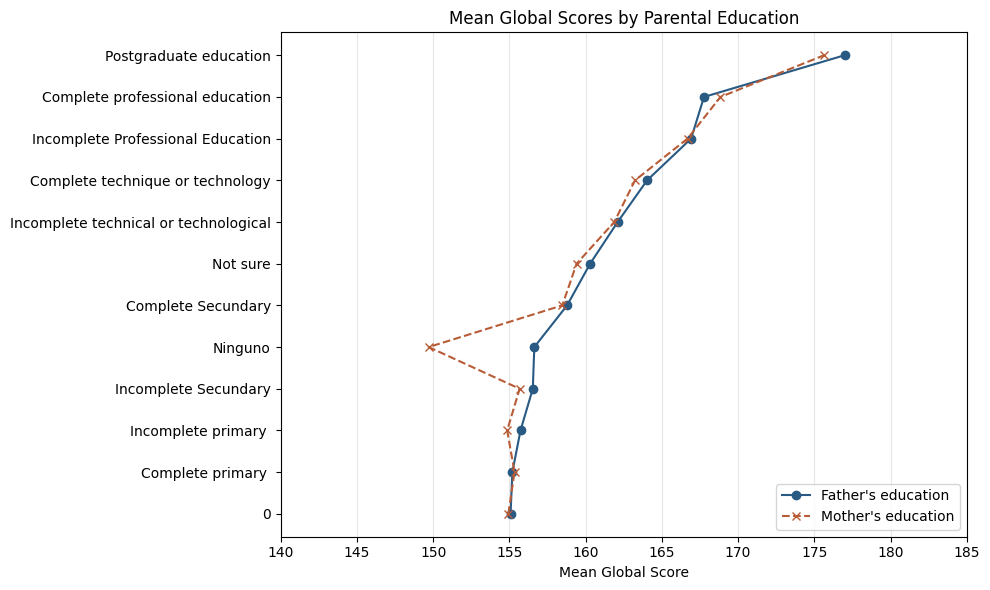

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    parent_means["Father's education"],
    parent_means.index,
    label="Father's education",
    color="#285A83",
    marker="o",
    linewidth=1.5
)

ax.plot(
    parent_means["Mother's education"],
    parent_means.index,
    label="Mother's education",
    color="#B85C38",
    marker="x",
    linestyle="--",
    linewidth=1.5
)

ax.set_title("Mean Global Scores by Parental Education")
ax.set_xlabel("Mean Global Score")
ax.set_ylabel("")
ax.set_xlim(140, 185)
ax.set_xticks(range(140, 186, 5))
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("Figure1_Parental_Education_Lines.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
from statsmodels.stats.oneway import anova_oneway

father_data = df.loc[~df["EDU_FATHER"].isin([0, "0", "Not sure"])]
mother_data = df.loc[~df["EDU_MOTHER"].isin([0, "0", "Not sure"])]

father_test = anova_oneway(
    father_data["G_SC"],
    groups=father_data["EDU_FATHER"],
    use_var="unequal"
)

mother_test = anova_oneway(
    mother_data["G_SC"],
    groups=mother_data["EDU_MOTHER"],
    use_var="unequal"
)

print("Father: students =", len(father_data))
print("Father: F =", father_test.statistic)
print("Father: degrees of freedom =", father_test.df)
print("Father: p =", father_test.pvalue)

print("Mother: students =", len(mother_data))
print("Mother: F =", mother_test.statistic)
print("Mother: degrees of freedom =", mother_test.df)
print("Mother: p =", mother_test.pvalue)

Father: students = 11613
Father: F = 109.85000747128731
Father: degrees of freedom = (9.0, np.float64(1787.0066680617667))
Father: p = 6.725963179630137e-164
Mother: students = 11844
Mother: F = 105.7514820167044
Mother: degrees of freedom = (9.0, np.float64(821.1061341929643))
Mother: p = 8.100041285190422e-131


Question 2

In [22]:
stratum_summary = df.groupby("STRATUM")["G_SC"].agg(["count", "mean", "median", "std"])
stratum_summary = stratum_summary.sort_values("mean", ascending=False)
stratum_summary.round(2)

,count,mean,median,std
STRATUM,,,,
Stratum 6,403,181.51,184.00,21.88
Stratum 5,633,177.39,179.00,21.54
Stratum 4,1578,172.00,174.00,21.47
Stratum 3,4045,163.82,164.00,21.69
Stratum 2,4029,158.20,158.00,22.28
0,14,154.00,152.50,21.32
Stratum 1,1709,152.35,152.00,21.94


<Axes: title={'center': 'Global Scores by Stratum'}, ylabel='Global Score'>

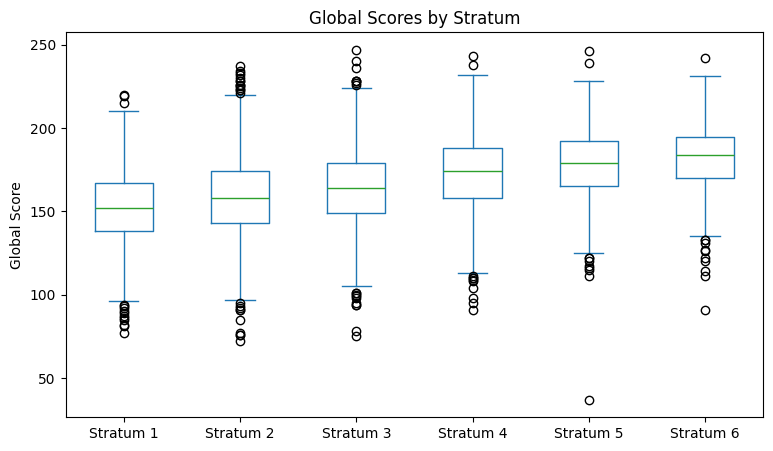

In [23]:
stratum_order = ["Stratum 1", "Stratum 2", "Stratum 3", "Stratum 4", "Stratum 5", "Stratum 6"]
stratum_scores = df.pivot(columns="STRATUM", values="G_SC")
stratum_scores = stratum_scores[stratum_order]
stratum_scores.plot.box(figsize=(9, 5), ylabel="Global Score", title="Global Scores by Stratum")

In [24]:
from scipy.stats import ttest_ind

stratum1 = df.loc[df["STRATUM"] == "Stratum 1", "G_SC"]
stratum6 = df.loc[df["STRATUM"] == "Stratum 6", "G_SC"]

result = ttest_ind(stratum1, stratum6, equal_var=False)

print("t statistic:", result.statistic)
print("p value:", result.pvalue)

t statistic: -24.05381277389611
p value: 2.6182340969083655e-90


In [25]:
from scipy.stats import f_oneway

stratum1 = df.loc[df["STRATUM"] == "Stratum 1", "G_SC"]
stratum2 = df.loc[df["STRATUM"] == "Stratum 2", "G_SC"]
stratum3 = df.loc[df["STRATUM"] == "Stratum 3", "G_SC"]
stratum4 = df.loc[df["STRATUM"] == "Stratum 4", "G_SC"]
stratum5 = df.loc[df["STRATUM"] == "Stratum 5", "G_SC"]
stratum6 = df.loc[df["STRATUM"] == "Stratum 6", "G_SC"]

anova_result = f_oneway(stratum1, stratum2, stratum3, stratum4, stratum5, stratum6)

print("F statistic:", anova_result.statistic)
print("p value:", anova_result.pvalue)

F statistic: 286.06371017527766
p value: 1.4255991296541535e-290


In [26]:
sel_summary = df.groupby("SEL")["G_SC"].agg(["count", "mean", "median", "std"])
sel_summary = sel_summary.sort_index()
sel_summary.round(2)

,count,mean,median,std
SEL,,,,
1,2138,155.47,155.00,21.80
2,4742,158.54,159.00,22.32
3,1491,162.30,162.00,22.02
4,4040,171.58,173.00,22.35


In [27]:
from scipy.stats import f_oneway

sel1 = df.loc[df["SEL"] == 1, "G_SC"]
sel2 = df.loc[df["SEL"] == 2, "G_SC"]
sel3 = df.loc[df["SEL"] == 3, "G_SC"]
sel4 = df.loc[df["SEL"] == 4, "G_SC"]

sel_test = f_oneway(sel1, sel2, sel3, sel4)

print("F statistic:", sel_test.statistic)
print("p value:", sel_test.pvalue)

F statistic: 346.65569015875366
p value: 3.421339735078031e-216


Question 3

In [28]:
df["GENDER"].value_counts(dropna=False)

,count
GENDER,
M,7368
F,5043


In [29]:
gender_summary = df.groupby("GENDER")["G_SC"].agg(["count", "mean", "median", "std"])
gender_summary = gender_summary.sort_values("mean", ascending=False)
gender_summary.round(2)

,count,mean,median,std
GENDER,,,,
M,7368,163.69,164.00,23.58
F,5043,161.28,162.00,22.33


In [30]:
from scipy.stats import ttest_ind

male_scores = df.loc[df["GENDER"] == "M", "G_SC"]
female_scores = df.loc[df["GENDER"] == "F", "G_SC"]

gender_test = ttest_ind(male_scores, female_scores, equal_var=False)

print("t statistic:", gender_test.statistic)
print("p value:", gender_test.pvalue)

t statistic: 5.777471574966612
p value: 7.785030938251425e-09


In [31]:
male_n = male_scores.count()
female_n = female_scores.count()

pooled_sd = (((male_n - 1) * male_scores.std() ** 2 + (female_n - 1) * female_scores.std() ** 2) / (male_n + female_n - 2)) ** 0.5

cohens_d = (male_scores.mean() - female_scores.mean()) / pooled_sd

print("Cohen's d:", round(cohens_d, 3))

Cohen's d: 0.105


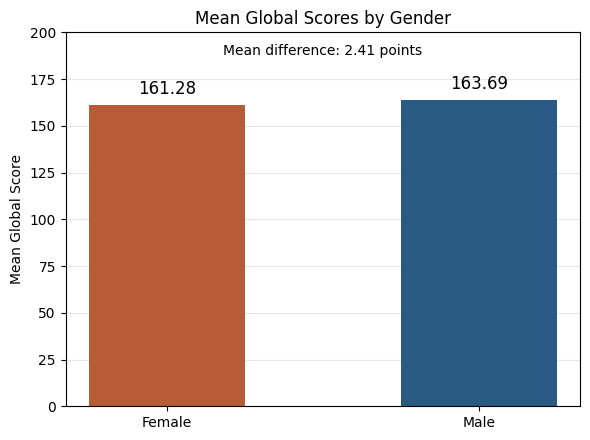

In [32]:
gender_means = df.groupby("GENDER")["G_SC"].mean()
gender_means = gender_means.reindex(["F", "M"])

difference = gender_means["M"] - gender_means["F"]

fig, ax = plt.subplots(figsize=(6, 4.5))

bars = ax.bar(
    ["Female", "Male"],
    gender_means.values,
    color=["#B85C38", "#285A83"],
    width=0.5
)

ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=12)

ax.set_title("Mean Global Scores by Gender")
ax.set_ylabel("Mean Global Score")
ax.set_ylim(0, 200)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

ax.text(
    0.5, 0.94,
    f"Mean difference: {difference:.2f} points",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout()
plt.savefig("Figure3_Gender_Means.png", dpi=300, bbox_inches="tight")
plt.show()

Implement code

In [33]:
program_count = df["ACADEMIC_PROGRAM"].value_counts()
program_count

,count
ACADEMIC_PROGRAM,
INDUSTRIAL ENGINEERING,5318
CIVIL ENGINEERING,3320
MECHANICAL ENGINEERING,1135
CHEMICAL ENGINEERING,1000
ELECTRONIC ENGINEERING,849
ELECTRIC ENGINEERING,278
MECHATRONICS ENGINEERING,82
CATASTRAL ENGINEERING AND GEODESY,78
PRODUCTION ENGINEERING,60


In [34]:
# Select the global score and university-level assessment scores
score_columns = ["G_SC", "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "FEP_PRO"]

# Calculate mean scores for each engineering program
program_summary = df.groupby("ACADEMIC_PROGRAM")[score_columns].mean()

# Include sample sizes to help identify results based on very few students
program_summary["Students"] = program_count

# Show larger programs first, rather than ranking programs by scores
program_summary = program_summary.sort_values("Students", ascending=False)

# Display scores to two decimal places for readability
program_summary.round(2)

,G_SC,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,Students
ACADEMIC_PROGRAM,,,,,,,,
INDUSTRIAL ENGINEERING,159.04,72.12,58.14,55.85,64.69,54.15,147.48,5318
CIVIL ENGINEERING,161.11,78.82,60.53,58.34,63.80,51.31,144.46,3320
MECHANICAL ENGINEERING,166.05,82.73,65.44,59.56,72.31,50.49,143.72,1135
CHEMICAL ENGINEERING,176.70,86.86,75.30,70.22,82.52,63.99,152.39,1000
ELECTRONIC ENGINEERING,166.87,82.14,68.49,63.84,73.05,51.16,145.87,849
ELECTRIC ENGINEERING,173.99,88.70,74.24,72.27,76.12,57.82,139.98,278
MECHATRONICS ENGINEERING,151.56,70.23,52.07,49.70,55.66,44.10,142.85,82
CATASTRAL ENGINEERING AND GEODESY,174.60,87.62,78.19,78.08,75.38,59.63,78.08,78
PRODUCTION ENGINEERING,172.90,83.47,73.63,71.03,80.27,56.62,135.32,60


In [35]:
# Check whether matching averages also reflect matching individual values
fep_check = df.groupby("ACADEMIC_PROGRAM")[["CC_PRO", "WC_PRO", "FEP_PRO"]].head(3)

# Show example records for one program with matching averages
df.loc[
    df["ACADEMIC_PROGRAM"] == "CATASTRAL ENGINEERING AND GEODESY",
    ["CC_PRO", "WC_PRO", "FEP_PRO"]
].head(10)

,CC_PRO,WC_PRO,FEP_PRO
711,19,55,19
1957,27,57,27
2007,77,40,77
2054,37,19,37
2072,91,80,91
2087,99,89,99
2106,45,79,45
2118,96,26,96
2134,97,82,97
2231,92,49,92


In [36]:
# Select all students in this program
program_data = df.loc[
    df["ACADEMIC_PROGRAM"] == "CATASTRAL ENGINEERING AND GEODESY"
]

# Count records with identical citizenship and engineering project scores
matching_scores = (program_data["CC_PRO"] == program_data["FEP_PRO"]).sum()

print("Total students:", len(program_data))
print("Students with matching scores:", matching_scores)

Total students: 78
Students with matching scores: 78


In [37]:
# Exclude FEP_PRO from interpretation pending clarification of duplicated values
reviewed_scores = ["G_SC", "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO"]

# Summarize the remaining scores by academic program
program_summary_reviewed = df.groupby("ACADEMIC_PROGRAM")[reviewed_scores].mean()

# Keep sample sizes visible so small groups are interpreted cautiously
program_summary_reviewed["Students"] = program_count

# Display larger programs first and round scores for readability
program_summary_reviewed.sort_values("Students", ascending=False).round(2)

,G_SC,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,Students
ACADEMIC_PROGRAM,,,,,,,
INDUSTRIAL ENGINEERING,159.04,72.12,58.14,55.85,64.69,54.15,5318
CIVIL ENGINEERING,161.11,78.82,60.53,58.34,63.80,51.31,3320
MECHANICAL ENGINEERING,166.05,82.73,65.44,59.56,72.31,50.49,1135
CHEMICAL ENGINEERING,176.70,86.86,75.30,70.22,82.52,63.99,1000
ELECTRONIC ENGINEERING,166.87,82.14,68.49,63.84,73.05,51.16,849
ELECTRIC ENGINEERING,173.99,88.70,74.24,72.27,76.12,57.82,278
MECHATRONICS ENGINEERING,151.56,70.23,52.07,49.70,55.66,44.10,82
CATASTRAL ENGINEERING AND GEODESY,174.60,87.62,78.19,78.08,75.38,59.63,78
PRODUCTION ENGINEERING,172.90,83.47,73.63,71.03,80.27,56.62,60
